<a href="https://colab.research.google.com/github/jumbokh/appliedNum_learn/blob/master/notebooks/solveFun.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

Text(0, 0.5, 'y')

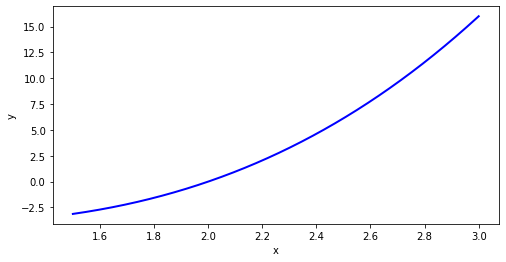

In [2]:
x = np.linspace(1.5, 3, 1000)
y = x**3-3*x-2
plt.figure(figsize=(8,4))
plt.plot(x,y,color="blue",linewidth=2)
plt.xlabel("x")
plt.ylabel("y")

In [3]:
# 数值求函数值
def solve_function(x):
    return x**3-3*x-2

In [4]:
# 二分法求根
def dichotomy(left, right,eps):
    middle = (left+right)/2
    count=0 # 统计迭代次数
    while abs(solve_function(middle))>eps:
        middle = (left+right)/2
        if solve_function(left)*solve_function(middle)<=0:
            right=middle
        else:
            left=middle
        count=count+1
    return count,middle

In [5]:
left=1.5
right=3
eps=0.00001
count,middle=dichotomy(left, right,eps)
print("迭代%d次得到的根是%f" %(count,middle))

迭代19次得到的根是2.000001


### 函數的導數

In [6]:
def solve_derivatives(x):
    return 3*x**2-3

In [7]:
# Newton's method
def Newton(x,eps):
    count=0
    while abs(solve_function(x))>eps:
        x=x-solve_function(x)/solve_derivatives(x)
        count=count+1
    return count,x

In [8]:
# 不动点法求根
def Fixed_Point(x,eps):
    count=0
    while abs(solve_function(x))>eps:
        x= (3*x+2)**(1/3)
        count=count+1
    return count,x

In [9]:
x=3
eps=0.0001
count,middle=Fixed_Point(x,eps)
print("迭代%d次得到的根是%f" %(count,middle))

迭代9次得到的根是2.000003


In [10]:
# 计算多个精度的迭代次数
N=11 #精度，小数点位数
epss=[0.1**x for x in range(1,N)]
left=1.5
right=3
Binary_count=[]
Newton_count=[]
FixedPoint_count=[]
for eps in epss:
    count,ans=dichotomy(left, right,eps)
    Binary_count.append(count)
    count,ans=Newton(right,eps)
    Newton_count.append(count)
    count,ans=Fixed_Point(right,eps)
    FixedPoint_count.append(count)

Text(0, 0.5, 'iterations')

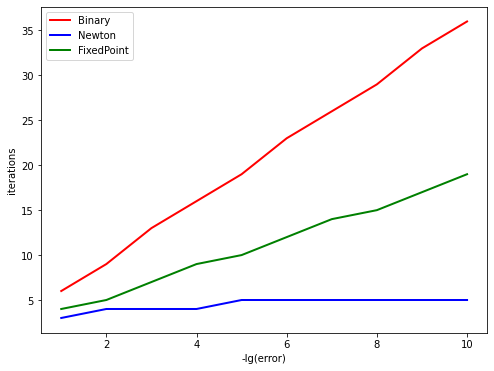

In [11]:
# 画图比较三种方法的性能
number=[x for x in range(1,N)]
plt.figure(figsize=(8,6))
line1,=plt.plot(number,Binary_count, label="Line 1",color="red",linewidth=2)
line2,=plt.plot(number,Newton_count, label="Line 2",color="blue",linewidth=2)
line3,=plt.plot(number,FixedPoint_count, label="Line 3",color="green",linewidth=2)
l1 = plt.legend([line1, line2,line3], ["Binary", "Newton","FixedPoint"], loc='upper left')
plt.xlabel("-lg(error)")
plt.ylabel("iterations")